# RouteVision：晶片版圖繞線壅塞熱點預測（期中 Milestone 訓練 Notebook）

**任務**：輸入 placement 後的版圖特徵圖（cell 密度、RUDY、腳位 RUDY、macro），預測每個 32×32 區塊在最終 global routing 後是否為壅塞熱點（區塊平均繞線使用率 ≥ 0.6）。

**比較的方法**：EDA 粗估（RUDY、eGR）、OpenCV 特徵 + Random Forest、MLP、CNN、多模態（影像 + 設計參數）、ViT（選配 U-Net）。

**切分方式**：依「設計」切分，測試設計完全不參與訓練，用來檢驗模型能不能用在沒看過的晶片上。

### 執行步驟（Colab，T4 GPU，約 30–40 分鐘）
1. 把 `RouteVision.zip` 上傳到 Google Drive 的 `MyDrive/`。
2. 「執行階段 → 變更執行階段類型」選 **T4 GPU**。
3. 「執行階段 → 全部執行」。訓練好的模型存在 Drive 的 `MyDrive/RouteVision/checkpoints/`，斷線後重跑會直接讀取，不會重新訓練。
4. 最後一格會下載 `RouteVision_results.zip`（模型、閾值、結果圖表、demo 範例）；解壓到本機專案資料夾後即可執行網頁 demo。

In [1]:
# 環境設定：掛載 Drive、解壓專案（只在第一次解壓）
import os, sys
from google.colab import drive
drive.mount('/content/drive')
PROJECT = '/content/drive/MyDrive/RouteVision'
if not os.path.exists(f'{PROJECT}/routevision'):
    !unzip -q -o /content/drive/MyDrive/RouteVision.zip -d /content/drive/MyDrive/
os.chdir(PROJECT); sys.path.insert(0, PROJECT)
%matplotlib inline
import torch
print('device:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU（請改用 T4 GPU）')

Mounted at /content/drive
device: Tesla T4


## 1. 資料：CircuitNet-N14（前處理後的檔案）
`data/processed/*.npz` 已包含在專案 zip 中。若檔案不存在，下一格會從 Hugging Face 下載原始資料並自動前處理（每個設計約 5–15 分鐘）。

In [2]:
DESIGNS = ['Vortex-small', 'nvdla-small', 'openc910-1']
TEST_DESIGN = 'Vortex-small'          # 完全不參與訓練的設計
missing = [d for d in DESIGNS if not os.path.exists(f'data/processed/{d}.npz')]
if missing:
    !python -m routevision.prepare --designs {' '.join(missing)} --raw_dir /content/raw --out_dir data/processed
from routevision import experiments as E
data, split, norm, stores = E.prepare('data/processed', DESIGNS, TEST_DESIGN, ckpt_dir='checkpoints')

train:  164 layouts,  10496 windows, hotspot rate 0.388, designs ['nvdla-small', 'openc910-1']
val  :   28 layouts,   1792 windows, hotspot rate 0.390, designs ['nvdla-small', 'openc910-1']
test :   96 layouts,   6144 windows, hotspot rate 0.232, designs ['Vortex-small']


## 2. 訓練與評估所有方法
第一次執行會訓練（MLP、CNN、多模態各約 3–5 分鐘，ViT 約 10–15 分鐘）；之後直接讀取 `checkpoints/`。閾值一律在 validation set 上決定，test set 只用來評估。

In [3]:
res = E.run(stores, ckpt_dir='checkpoints', out_dir='outputs', methods=('MLP', 'CNN', 'Multimodal', 'ViT'), use_unet=False)
res['table']

  [MLP] epoch  1/15 | loss 0.4789 | val ROC-AUC 0.9808 | 3s
  [MLP] epoch  2/15 | loss 0.2551 | val ROC-AUC 0.9769 | 2s
  [MLP] epoch  3/15 | loss 0.2141 | val ROC-AUC 0.9827 | 1s
  [MLP] epoch  4/15 | loss 0.1927 | val ROC-AUC 0.9849 | 2s
  [MLP] epoch  5/15 | loss 0.1868 | val ROC-AUC 0.9841 | 2s
  [MLP] epoch  6/15 | loss 0.1759 | val ROC-AUC 0.9842 | 2s
  [MLP] epoch  7/15 | loss 0.1561 | val ROC-AUC 0.9875 | 2s
  [MLP] epoch  8/15 | loss 0.1478 | val ROC-AUC 0.9879 | 2s
  [MLP] epoch  9/15 | loss 0.1416 | val ROC-AUC 0.9881 | 2s
  [MLP] epoch 10/15 | loss 0.1286 | val ROC-AUC 0.9894 | 2s
  [MLP] epoch 11/15 | loss 0.1207 | val ROC-AUC 0.9884 | 2s
  [MLP] epoch 12/15 | loss 0.1135 | val ROC-AUC 0.9885 | 2s
  [MLP] epoch 13/15 | loss 0.1099 | val ROC-AUC 0.9878 | 2s
  [MLP] epoch 14/15 | loss 0.1057 | val ROC-AUC 0.9882 | 2s
  [MLP] epoch 15/15 | loss 0.1052 | val ROC-AUC 0.9883 | 2s
  [CNN] epoch  1/15 | loss 0.4264 | val ROC-AUC 0.9821 | 8s
  [CNN] epoch  2/15 | loss 0.2343 | val 

100%|██████████| 330M/330M [00:02<00:00, 137MB/s]


  [ViT] epoch  1/3 | loss 0.2450 | val ROC-AUC 0.9933 | 108s
  [ViT] epoch  2/3 | loss 0.0839 | val ROC-AUC 0.9969 | 110s
  [ViT] epoch  3/3 | loss 0.0144 | val ROC-AUC 0.9976 | 111s


,method,ROC-AUC,PR-AUC,F1(hotspot),Macro-F1,Precision,Recall,Accuracy,threshold (from val)
0,RUDY (EDA estimate),0.8364,0.4793,0.6062,0.7181,0.4921,0.7892,0.7625,0.0104
1,eGR (EDA estimate),0.8942,0.6878,0.6489,0.7696,0.6318,0.6669,0.8328,0.2993
2,OpenCV + RandomForest,0.9442,0.8422,0.7299,0.8096,0.6065,0.9164,0.8429,0.4618
3,MLP,0.9014,0.6758,0.6728,0.7599,0.5285,0.9255,0.7915,0.6754
4,CNN,0.9226,0.7689,0.6587,0.7856,0.7625,0.5798,0.8608,0.4406
5,Multimodal,0.9499,0.8191,0.7393,0.8346,0.8147,0.6767,0.8895,0.5445
6,ViT,0.9425,0.8336,0.7443,0.8350,0.7668,0.7231,0.8849,0.4414


## 3. 結果圖表

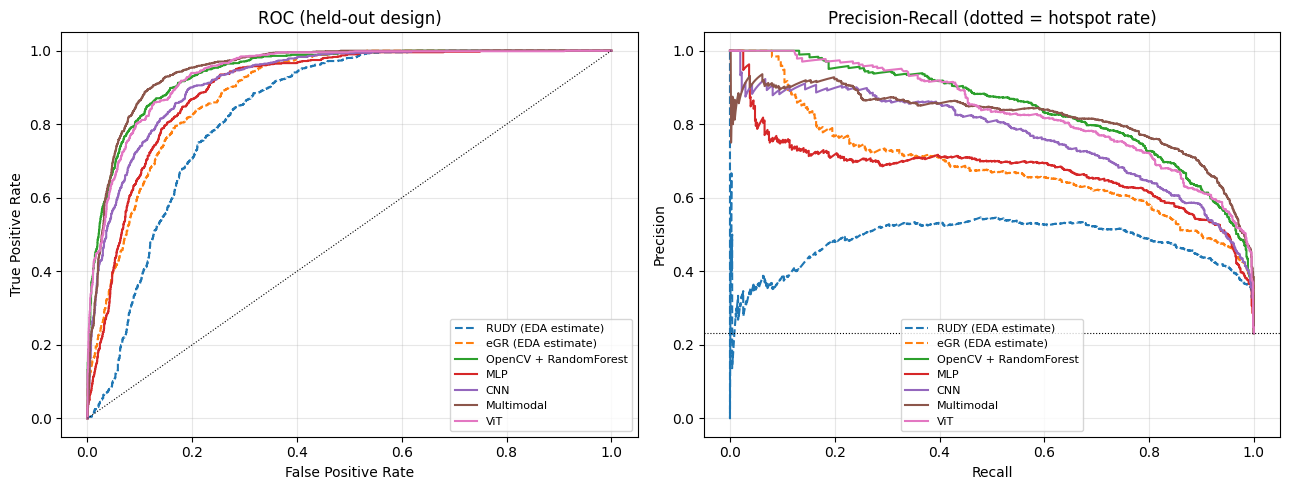

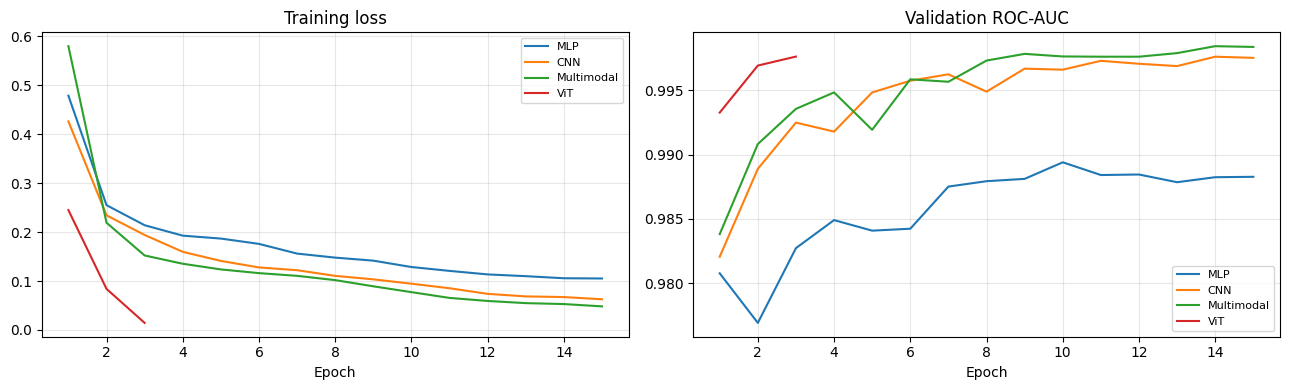

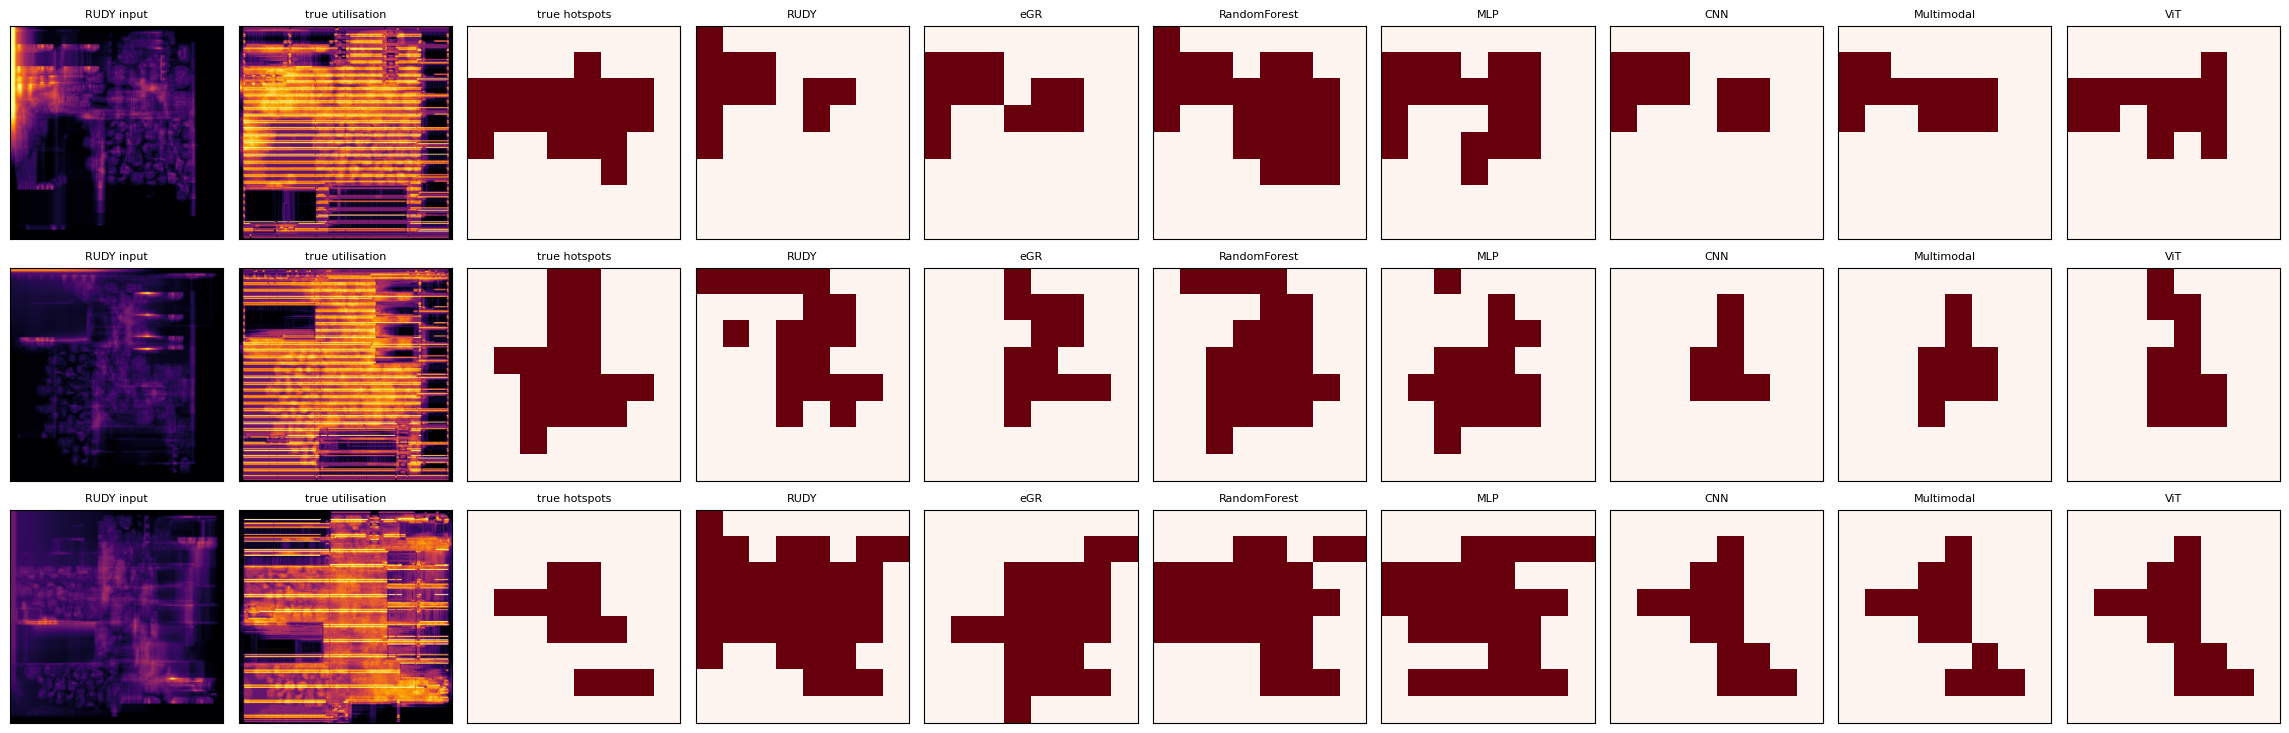

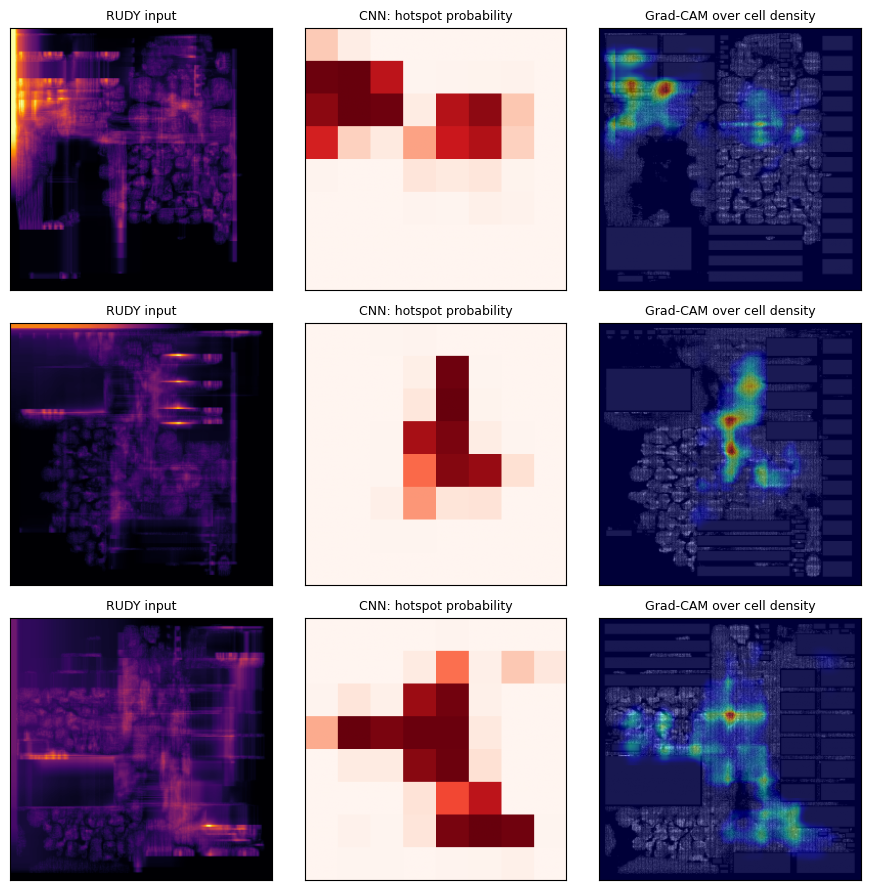

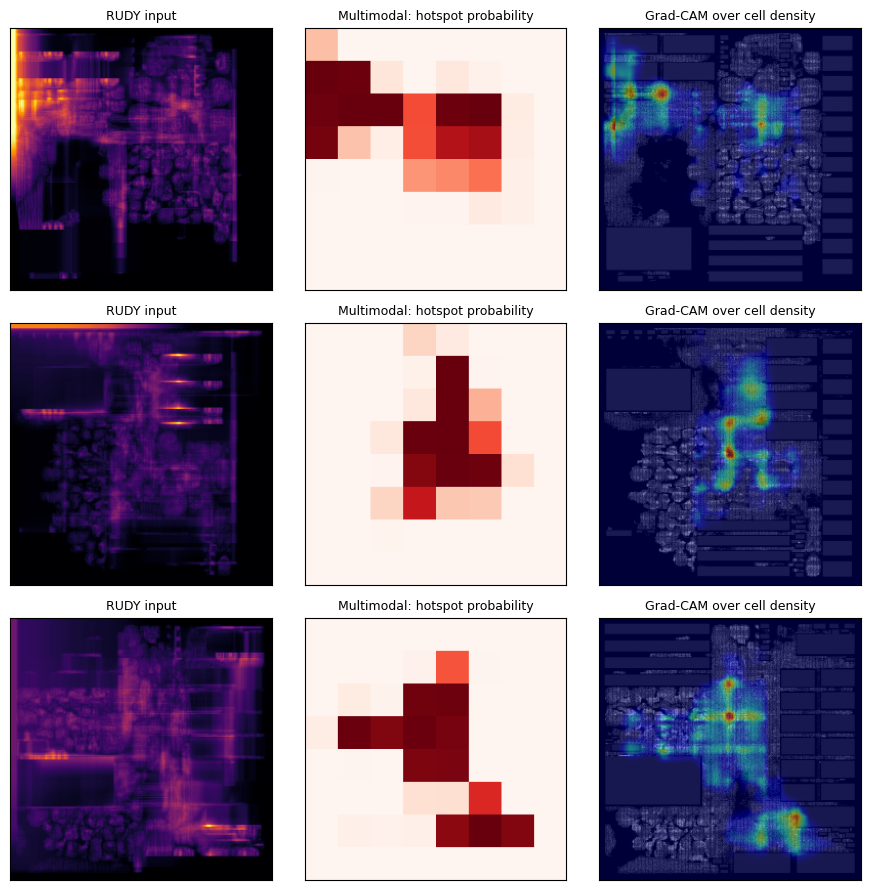

In [4]:
import matplotlib.pyplot as plt
yt = stores['test'].flat('y')
E.plot_curves(yt, res['scores'], 'outputs/roc_pr_curves.png'); plt.show()
E.plot_history(res['history'], 'outputs/training_curves.png'); plt.show()
show = [0, len(stores['test'].items) // 2, len(stores['test'].items) - 1]
E.plot_layouts(stores['test'], res['scores'], res['thresholds'], show, 'outputs/hotspot_maps.png'); plt.show()
E.plot_gradcam(res['models']['CNN'], stores['test'], show, 'outputs/gradcam_cnn.png', 'CNN'); plt.show()
E.plot_gradcam(res['models']['Multimodal'], stores['test'], show, 'outputs/gradcam_multimodal.png', 'Multimodal'); plt.show()

## 4.（選配）U-Net：直接預測整張繞線使用率圖
約 5–10 分鐘。不跑也不影響期中 demo。

In [5]:
RUN_UNET = False
if RUN_UNET:
    res_u = E.run(stores, ckpt_dir='checkpoints', out_dir='outputs', methods=('MLP', 'CNN', 'Multimodal', 'ViT'), use_unet=True)
    display(res_u['table'])

## 5. 打包下載（模型、閾值、圖表、demo 範例）

In [6]:
os.makedirs('demo', exist_ok=True)
E.export_demo(data, split, 'demo/demo_layouts.npz')
!cd {PROJECT} && rm -f /content/RouteVision_results.zip && zip -q -r /content/RouteVision_results.zip checkpoints outputs demo
from google.colab import files
files.download('/content/RouteVision_results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>